# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

Haz doble clic aquí y escribe de dónde salen tus datos (con el enlace), qué es cada fila y qué pregunta quieres responder.

## 0. Comprobación

In [127]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [128]:
# 1.1 Cargo las ofertas de trabajo desde el CSV de la carpeta datos y enseño las 5 primeras filas
data_jobs = pd.read_csv("datos/data_jobs.csv")
data_jobs.head()


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


**1.2** ¿Cuántas filas y columnas tiene?

In [129]:
# 1.2 Tamaño de la tabla: (filas, columnas)
data_jobs.shape

(785741, 17)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [130]:
# 1.3 Tipo de cada columna y cuántos valores no vacíos tiene (si son menos que las filas, hay huecos)
data_jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 785741 entries, 0 to 785740
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   job_title_short        785741 non-null  str    
 1   job_title              785740 non-null  str    
 2   job_location           784696 non-null  str    
 3   job_via                785733 non-null  str    
 4   job_schedule_type      773074 non-null  str    
 5   job_work_from_home     785741 non-null  bool   
 6   search_location        785741 non-null  str    
 7   job_posted_date        785741 non-null  str    
 8   job_no_degree_mention  785741 non-null  bool   
 9   job_health_insurance   785741 non-null  bool   
 10  job_country            785692 non-null  str    
 11  salary_rate            33067 non-null   str    
 12  salary_year_avg        22003 non-null   float64
 13  salary_hour_avg        10662 non-null   float64
 14  company_name           785723 non-null  str    

**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [131]:
# 1.4 Me quedo solo con las ofertas de España en una tabla nueva: ofertas
# .copy() hace una copia aparte para no tocar la tabla original (no lo hemos visto en clase)
ofertas = data_jobs[data_jobs["job_country"] == "Spain"].copy()
ofertas.shape

(25100, 17)

In [132]:
# 1.4 Me quedo con las 10 columnas que sirven para mis preguntas y para los filtros de la app
# Quito país y ubicación de búsqueda (siempre es España), los salarios (casi todos vacíos),
# el seguro médico (solo 3 ofertas lo mencionan) y job_type_skills (repite las habilidades)
ofertas = ofertas[["job_title_short", "job_title", "job_location", "job_work_from_home", "job_schedule_type", "job_skills", "company_name", "job_posted_date", "job_via", "job_no_degree_mention"]]
ofertas.shape

(25100, 10)

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [133]:
# 1.5 Pongo los nombres de las columnas en español, cortos y sin tildes
ofertas.columns = ["puesto", "titulo", "ubicacion", "remoto", "jornada", "habilidades", "empresa", "fecha", "portal", "sin_titulo"]
ofertas.head()

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo
115,Data Scientist,Azure Big Data Engineer,"Madrid, Spain",False,Full-time,"['scala', 'azure']",FHIOS Smart Knowledge,2023-03-02 13:24:09,via BeBee,False
124,Data Scientist,DATA SCIENTIST,"Madrid, Spain",False,Full-time,"['sql', 'python', 'r', 'hadoop', 'spark', 'git...",Joboss,2023-05-03 13:46:14,via LinkedIn,False
226,Data Engineer,Data Engineer con Python,Spain,False,Full-time,['python'],Keyrus,2023-01-20 14:12:16,via LinkedIn,True
258,Data Engineer,Data Engineer,"Barcelona, Spain",False,Full-time,"['python', 'sql', 'postgresql', 'gcp', 'aws', ...",Michael Page,2023-02-26 13:10:34,via BeBee,True
264,Senior Data Engineer,Senior Engineer- MS,"Madrid, Spain",False,Full-time,['outlook'],NTT,2023-02-08 21:45:53,via BeBee,False


Lo que he visto y lo que he decidido:

- La tabla original tiene 785.741 ofertas de todo el mundo y 17 columnas. Me quedo con las de España: 25.100.
- La fecha y las habilidades vienen como texto, no como fecha ni como lista.
- Quito 7 columnas: el país y la ubicación de búsqueda (después del filtro siempre es España), los tres de salario (más del 99 % vacíos), el seguro médico (solo 3 ofertas lo mencionan) y job_type_skills (son las mismas habilidades que job_skills, agrupadas por tipo).
- Pongo los nombres de las columnas en español, cortos y sin tildes.
- El tipo de puesto no siempre coincide con el título de la oferta (por ejemplo, un "Data Scientist" cuyo título es "Azure Big Data Engineer").

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [134]:
# 2.1 Cuento cuántos huecos tiene cada columna
ofertas.isnull().sum()

puesto            0
titulo            0
ubicacion         0
remoto            0
jornada          99
habilidades    3083
empresa           0
fecha             0
portal            0
sin_titulo        0
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [135]:
# 2.2 Porcentaje de huecos de cada columna, redondeado a un decimal
(ofertas.isnull().mean()*100).round(1)

puesto          0.0
titulo          0.0
ubicacion       0.0
remoto          0.0
jornada         0.4
habilidades    12.3
empresa         0.0
fecha           0.0
portal          0.0
sin_titulo      0.0
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [136]:
# 2.3 Quito las filas sin jornada: son solo 99 ofertas (0,4 %), no cambian los resultados
ofertas = ofertas.dropna(subset=["jornada"])
ofertas.shape

(25001, 10)

**Los huecos de habilidades (12,3 %) los dejo a propósito: esas ofertas me siguen sirviendo para analizar el puesto, la ubicación, el remoto y la jornada. Cuando cuente las habilidades, solo usaré las ofertas que las tienen. Si las quitara perdería información, y si las rellenara me estaría inventando un dato.**

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [137]:
# 2.4 Compruebo que ya no quedan huecos en jornada; los de habilidades los dejo a propósito
ofertas.isnull().sum()

puesto            0
titulo            0
ubicacion         0
remoto            0
jornada           0
habilidades    3063
empresa           0
fecha             0
portal            0
sin_titulo        0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [138]:
# 2.5 Busco huecos disfrazados en las columnas de texto, empezando por el tipo de puesto
ofertas["puesto"].value_counts()

puesto
Data Engineer                6720
Data Scientist               5560
Data Analyst                 5152
Software Engineer            1574
Business Analyst             1500
Senior Data Engineer         1374
Senior Data Scientist        1344
Senior Data Analyst           615
Machine Learning Engineer     597
Cloud Engineer                565
Name: count, dtype: int64

In [139]:
# 2.5 Tipos de jornada: no hay huecos disfrazados, pero hay muchas combinaciones
ofertas["jornada"].value_counts()

jornada
Full-time                                24010
Contractor                                 284
Internship                                 272
Part-time                                  199
Full-time and Internship                    53
Full-time and Part-time                     50
Temp work                                   40
Full-time and Temp work                     30
Full-time and Contractor                    16
Part-time and Internship                    14
Contractor and Temp work                     9
Full-time, Part-time, and Internship         6
Full-time, Part-time, and Temp work          3
Part-time and Contractor                     3
Part-time and Temp work                      3
Full-time, Contractor, and Temp work         2
Temp work and Internship                     2
Full-time and Per diem                       2
Full-time, Temp work, and Internship         1
Contractor, Temp work, and Internship        1
Contractor and Full-time                     1
Name:

In [140]:
# 2.5 Ubicaciones: "Spain" (no dice la ciudad) y "Anywhere" (en cualquier sitio) no son ciudades
ofertas["ubicacion"].value_counts()

ubicacion
Madrid, Spain                 9762
Barcelona, Spain              4201
Spain                         2920
Anywhere                      2639
Valencia, Spain                783
                              ... 
San Fernando, Spain              1
La Puebla del Río, Spain         1
Sant Joan d'Alacant, Spain       1
Alburquerque, Spain              1
Santa Bàrbara, Spain             1
Name: count, Length: 380, dtype: int64

In [141]:
# 2.5 Cambio "Spain" por "Sin especificar" y "Anywhere" por "Remoto" para que se entiendan en la app
ofertas["ubicacion"] = ofertas["ubicacion"].replace({"Spain": "Sin especificar", "Anywhere": "Remoto"})

In [142]:
# 2.5 Compruebo el cambio: ya no aparecen "Spain" ni "Anywhere"
ofertas["ubicacion"].value_counts()

ubicacion
Madrid, Spain                 9762
Barcelona, Spain              4201
Sin especificar               2920
Remoto                        2639
Valencia, Spain                783
                              ... 
San Fernando, Spain              1
La Puebla del Río, Spain         1
Sant Joan d'Alacant, Spain       1
Alburquerque, Spain              1
Santa Bàrbara, Spain             1
Name: count, Length: 380, dtype: int64

In [143]:
# 2.5 Portales donde se publicó la oferta: no hay huecos, pero todos empiezan por "via "
ofertas["portal"].value_counts()

portal
via BeBee                                                11900
via LinkedIn                                              5893
via Trabajo.org                                           2559
via Indeed                                                 857
via Recruit.net                                            752
                                                         ...  
via Aicareers                                                1
via Jobs MAPFRE                                              1
via Best Suitable Jobs For Your Skills And Experience        1
via Jobs At Nestlé | Nestlé Global - Nestle                  1
via Www.finden.at                                            1
Name: count, Length: 303, dtype: int64

Lo que he visto y lo que he decidido:

- Solo hay huecos en dos columnas: jornada (99 ofertas, 0,4 %) y habilidades (3.083 ofertas, 12,3 %).
- Quito las 99 ofertas sin jornada, porque son muy pocas y no cambian los resultados. Quedan 25.001.
- Dejo a propósito los huecos de habilidades: esas ofertas me sirven para el resto del análisis y no quiero inventarme el dato.
- En ubicación hay un hueco disfrazado: "Spain" significa que la oferta no dice la ciudad. Lo cambio por "Sin especificar". "Anywhere" no es un hueco, significa que se puede trabajar desde cualquier sitio: lo cambio por "Remoto".
- La jornada tiene 21 combinaciones distintas, pero el 96 % son "Full-time".
- Todos los portales empiezan por "via " (pendiente de decidir si lo quito).

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [144]:
ofertas.duplicated().sum()

np.int64(1)

**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [145]:
ofertas[ofertas.duplicated(keep=False)]

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo
469737,Data Analyst,Data Analyst,"Madrid, Spain",False,Full-time,NaN,Randstad,2023-06-01 14:46:27,via BeBee,True
484337,Data Analyst,Data Analyst,"Madrid, Spain",False,Full-time,NaN,Randstad,2023-06-01 14:46:27,via BeBee,True


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [146]:
ofertas = ofertas.drop_duplicates()
ofertas.shape

(25000, 10)

Lo que he visto y lo que he decidido:

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

In [147]:
ofertas["habilidades"] = ofertas["habilidades"].str.strip("[]").str.replace("'", "").str.split(", ")
ofertas.head()

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo
115,Data Scientist,Azure Big Data Engineer,"Madrid, Spain",False,Full-time,"[scala, azure]",FHIOS Smart Knowledge,2023-03-02 13:24:09,via BeBee,False
124,Data Scientist,DATA SCIENTIST,"Madrid, Spain",False,Full-time,"[sql, python, r, hadoop, spark, git, jira]",Joboss,2023-05-03 13:46:14,via LinkedIn,False
226,Data Engineer,Data Engineer con Python,Sin especificar,False,Full-time,[python],Keyrus,2023-01-20 14:12:16,via LinkedIn,True
258,Data Engineer,Data Engineer,"Barcelona, Spain",False,Full-time,"[python, sql, postgresql, gcp, aws, linux]",Michael Page,2023-02-26 13:10:34,via BeBee,True
264,Senior Data Engineer,Senior Engineer- MS,"Madrid, Spain",False,Full-time,[outlook],NTT,2023-02-08 21:45:53,via BeBee,False


In [148]:
ofertas["num_habilidades"] = ofertas["habilidades"].str.len()

In [149]:
ofertas.head()

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo,num_habilidades
115,Data Scientist,Azure Big Data Engineer,"Madrid, Spain",False,Full-time,"[scala, azure]",FHIOS Smart Knowledge,2023-03-02 13:24:09,via BeBee,False,2.0
124,Data Scientist,DATA SCIENTIST,"Madrid, Spain",False,Full-time,"[sql, python, r, hadoop, spark, git, jira]",Joboss,2023-05-03 13:46:14,via LinkedIn,False,7.0
226,Data Engineer,Data Engineer con Python,Sin especificar,False,Full-time,[python],Keyrus,2023-01-20 14:12:16,via LinkedIn,True,1.0
258,Data Engineer,Data Engineer,"Barcelona, Spain",False,Full-time,"[python, sql, postgresql, gcp, aws, linux]",Michael Page,2023-02-26 13:10:34,via BeBee,True,6.0
264,Senior Data Engineer,Senior Engineer- MS,"Madrid, Spain",False,Full-time,[outlook],NTT,2023-02-08 21:45:53,via BeBee,False,1.0


**4.1** Haz el describe. ¿Qué te llama la atención?

In [152]:
ofertas["num_habilidades"].describe()

count    21938.000000
mean         5.390601
std          3.638694
min          1.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         35.000000
Name: num_habilidades, dtype: float64

**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [158]:
print(ofertas["num_habilidades"].mean().round(2))
print(ofertas["num_habilidades"].median().round(2))

5.39
5.0


**4.3** Dibuja su histograma.

<Axes: >

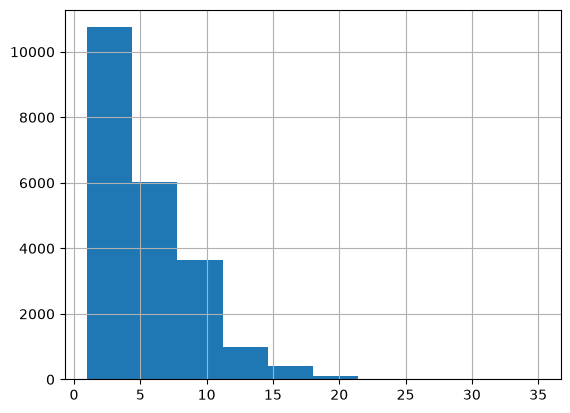

In [160]:
ofertas["num_habilidades"].hist()

**4.4** Haz lo mismo con otra columna de números.

In [ ]:
# No tengo más columnas de números

Lo que he visto y lo que he decidido:

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

**5.3** Haz el diagrama de caja de esa columna.

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

Lo que he visto y lo que he decidido:

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

**6.2** Dibújalo en barras.

Lo que he visto y lo que he decidido:

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

**7.2** Haz otra comparación con otra columna de grupos.

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

Lo que he visto y lo que he decidido:

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

**8.2** Haz el gráfico de puntos de esas dos columnas.

Lo que he visto y lo que he decidido:

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

Escribe aquí tus hallazgos.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.